# EN3160 Assignment 02: Fitting and Alignment
**Name:** Kavin Sulakshitha Gunasekara  
**Index:** 230211E
**GitHub:** https://github.com/gunasekaraks/YOUR_REPOSITORY



In [4]:
from pathlib import Path
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import minimize
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (6.4, 2.6),
    "figure.dpi": 110,
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "legend.fontsize": 6,
    "savefig.bbox": "tight",
    "figure.constrained_layout.use": True,
})

IMAGE_DIR = Path("images")

def read_image(path, flag=cv.IMREAD_COLOR):
    image = cv.imread(str(path), flag)
    if image is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return image

def show_image(ax, image, title="", gray=False):
    if image.ndim == 2 or gray:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

## 1. Sunflower detection using LoG



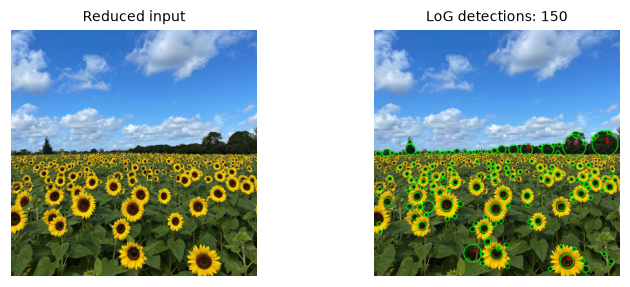

Sigma range: 2.0-20.0 pixels (24 scales)


,x,y,radius_px,sigma,response
0,338,165,18.951,13.400,0.247
1,293,169,17.146,12.124,0.246
2,144,326,12.698,8.979,0.166
3,282,338,10.394,7.349,0.349
4,223,174,9.403,6.649,0.251


In [7]:
sunflower = read_image(
    IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg",
    cv.IMREAD_REDUCED_COLOR_4
)
gray = cv.cvtColor(sunflower, cv.COLOR_BGR2GRAY).astype(float) / 255.0

# Initial settings: tune after inspecting the supplied image.
sigmas = np.geomspace(2.0, 20.0, 24)
relative_threshold = 0.18
max_detections = 150

responses = np.stack([
    sigma**2 * gaussian_laplace(gray, sigma)
    for sigma in sigmas
])

# Positive responses detect dark blobs.
# For bright blobs instead, use: responses = -responses
peaks = (
    (responses == maximum_filter(responses, size=(3, 3, 3)))
    & (responses > relative_threshold * responses.max())
)
candidates = np.argwhere(peaks)
scores = responses[peaks]
order = np.argsort(scores)[::-1]

blobs = []
height, width = gray.shape

for k in order:
    scale_index, y, x = candidates[k]
    sigma = sigmas[scale_index]
    radius = np.sqrt(2) * sigma

    # Exclude circles cut off by image boundaries.
    if min(x, y, width - 1 - x, height - 1 - y) < radius:
        continue

    # Greedy suppression of duplicate/strongly overlapping detections.
    if any(np.hypot(x - bx, y - by) < 0.7 * (radius + br)
           for bx, by, br, _, _ in blobs):
        continue

    blobs.append((x, y, radius, sigma, responses[scale_index, y, x]))
    if len(blobs) >= max_detections:
        break

blob_table = pd.DataFrame(
    blobs, columns=["x", "y", "radius_px", "sigma", "response"]
).sort_values("radius_px", ascending=False).reset_index(drop=True)

annotated = sunflower.copy()
for x, y, radius, sigma, score in blobs:
    cv.circle(annotated, (int(x), int(y)), round(radius),
              (0, 255, 0), 1, cv.LINE_AA)

for rank, row in blob_table.head(5).iterrows():
    cv.putText(annotated, str(rank + 1),
               (int(row.x), int(row.y)), cv.FONT_HERSHEY_SIMPLEX,
               0.4, (0, 0, 255), 1, cv.LINE_AA)

fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.5))
show_image(axes[0], sunflower, "Reduced input")
show_image(axes[1], annotated, f"LoG detections: {len(blobs)}")
plt.show()

print(f"Sigma range: {sigmas.min():.1f}-{sigmas.max():.1f} pixels "
      f"({len(sigmas)} scales)")
display(blob_table.head(5).round(3))

## 2. Sequential RANSAC fitting



In [ ]:

np.random.seed(0)

N = 100
half_n = N // 2
r_gt = 10
center_gt = np.array([2.0, 3.0])

t = np.random.uniform(0, 2*np.pi, half_n)
noise = (r_gt / 16) * np.random.randn(half_n)

X_circ = center_gt + np.column_stack([
    (r_gt + noise) * np.cos(t),
    (r_gt + noise) * np.sin(t)
])

x = np.linspace(-12, 12, half_n)
m_gt, intercept_gt = -1, 2
y = m_gt*x + intercept_gt + np.random.randn(half_n)

X_line = np.column_stack([x, y])
X = np.vstack([X_circ, X_line])

rng = np.random.default_rng(42)

In [9]:
def line_from_two(points):
    direction = points[1] - points[0]
    length = np.linalg.norm(direction)
    if length < 1e-10:
        return None

    normal = np.array([-direction[1], direction[0]]) / length
    d = normal @ points[0]

    if d < 0:
        normal, d = -normal, -d
    return np.r_[normal, d]


def fit_line_tls(points):
    centroid = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points - centroid, full_matrices=False)
    normal = vt[-1]
    normal /= np.linalg.norm(normal)
    d = normal @ centroid

    if d < 0:
        normal, d = -normal, -d
    return np.r_[normal, d]


def line_error(points, model):
    return np.abs(points @ model[:2] - model[2])


def circle_from_three(points):
    p0, p1, p2 = points
    A = 2 * np.vstack([p1 - p0, p2 - p0])
    rhs = np.array([
        p1 @ p1 - p0 @ p0,
        p2 @ p2 - p0 @ p0
    ])

    # Reject collinear or numerically unstable samples.
    if np.linalg.cond(A) > 1e8:
        return None

    center = np.linalg.solve(A, rhs)
    radius = np.linalg.norm(p0 - center)
    if not np.isfinite(radius) or radius <= 0:
        return None

    return np.r_[center, radius]


def circle_error(points, model):
    return np.abs(
        np.linalg.norm(points - model[:2], axis=1) - model[2]
    )


def fit_circle(points, initial):
    def objective(model):
        residual = (
            np.linalg.norm(points - model[:2], axis=1) - model[2]
        )
        return np.mean(residual**2)

    result = minimize(
        objective, initial, method="L-BFGS-B",
        bounds=[(None, None), (None, None), (1e-8, None)]
    )
    if not result.success:
        raise RuntimeError(f"Circle refinement failed: {result.message}")
    return result.x


def ransac(points, sample_size, make_model, error,
           threshold, min_inliers, trials, rng):
    """Hand-coded RANSAC: maximize consensus, then minimize inlier MSE."""
    if len(points) < max(sample_size, min_inliers):
        raise ValueError("Too few points for the required consensus.")

    best = None
    best_key = (-1, -np.inf)

    for _ in range(trials):
        sample_ids = rng.choice(len(points), sample_size, replace=False)
        model = make_model(points[sample_ids])
        if model is None:
            continue

        residual = error(points, model)
        mask = residual < threshold
        count = int(mask.sum())

        if count < min_inliers:
            continue

        key = (count, -np.mean(residual[mask]**2))
        if key > best_key:
            best_key = key
            best = {
                "model": model.copy(),
                "mask": mask.copy(),
                "sample_ids": sample_ids.copy()
            }

    if best is None:
        raise RuntimeError(
            "No valid consensus. Inspect thresholds/minimum consensus."
        )
    return best

In [10]:
line_threshold = 1.5
circle_threshold = 1.5
trials = 3000

line_result = ransac(
    X, 2, line_from_two, line_error,
    line_threshold, 30, trials, rng
)

# Refine on the winning consensus, then reclassify once.
line_model = fit_line_tls(X[line_result["mask"]])
line_mask = line_error(X, line_model) < line_threshold
if line_mask.sum() < 30:
    raise RuntimeError("Refined line has insufficient consensus.")

remaining_ids = np.flatnonzero(~line_mask)
remaining = X[remaining_ids]

circle_result = ransac(
    remaining, 3, circle_from_three, circle_error,
    circle_threshold, 25, trials, rng
)

circle_model = fit_circle(
    remaining[circle_result["mask"]],
    circle_result["model"]
)
local_circle_mask = circle_error(remaining, circle_model) < circle_threshold
if local_circle_mask.sum() < 25:
    raise RuntimeError("Refined circle has insufficient consensus.")

circle_mask = np.zeros(len(X), dtype=bool)
circle_mask[remaining_ids[local_circle_mask]] = True

line_sample = X[line_result["sample_ids"]]
circle_sample = remaining[circle_result["sample_ids"]]

summary = pd.DataFrame([
    {
        "Model": "Line",
        "Parameters": (
            f"a={line_model[0]:.3f}, b={line_model[1]:.3f}, "
            f"d={line_model[2]:.3f}"
        ),
        "Inliers": int(line_mask.sum()),
        "RMSE": np.sqrt(np.mean(line_error(X[line_mask], line_model)**2))
    },
    {
        "Model": "Circle",
        "Parameters": (
            f"cx={circle_model[0]:.3f}, cy={circle_model[1]:.3f}, "
            f"r={circle_model[2]:.3f}"
        ),
        "Inliers": int(circle_mask.sum()),
        "RMSE": np.sqrt(
            np.mean(circle_error(X[circle_mask], circle_model)**2)
        )
    }
])
display(summary.round(3))

print(f"Line normal magnitude: {np.linalg.norm(line_model[:2]):.6f}")
print(f"Circle centre error: "
      f"{np.linalg.norm(circle_model[:2] - center_gt):.3f}")
print(f"Circle radius error: {abs(circle_model[2] - r_gt):.3f}")

,Model,Parameters,Inliers,RMSE
0,Line,"a=0.716, b=0.698, d=1.562",54,0.675
1,Circle,"cx=1.949, cy=2.988, r=9.892",46,0.592


Line normal magnitude: 1.000000
Circle centre error: 0.052
Circle radius error: 0.108


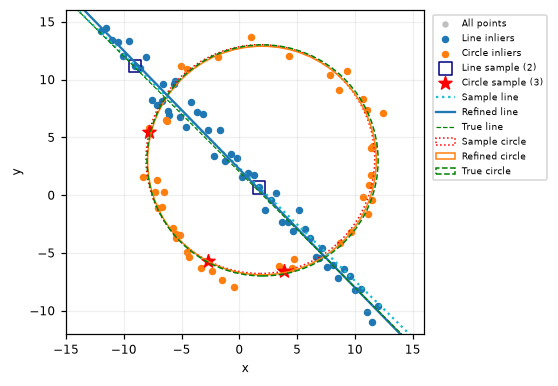

In [11]:
def draw_line(ax, model, limits, **kwargs):
    a, b, d = model
    if abs(b) > 1e-8:
        xx = np.array(limits)
        ax.plot(xx, (d - a*xx)/b, **kwargs)
    else:
        ax.axvline(d/a, **kwargs)


fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.scatter(*X.T, s=10, color="0.75", label="All points")
ax.scatter(*X[line_mask].T, s=15, color="tab:blue", label="Line inliers")
ax.scatter(*X[circle_mask].T, s=15, color="tab:orange",
           label="Circle inliers")

ax.scatter(*line_sample.T, s=65, marker="s", facecolors="none",
           edgecolors="navy", label="Line sample (2)")
ax.scatter(*circle_sample.T, s=80, marker="*", color="red",
           label="Circle sample (3)")

limits = (-15, 16)
draw_line(ax, line_result["model"], limits,
          color="tab:cyan", linestyle=":", label="Sample line")
draw_line(ax, line_model, limits,
          color="tab:blue", linewidth=1.5, label="Refined line")
draw_line(ax, np.array([1, 1, 2])/np.sqrt(2), limits,
          color="green", linestyle="--", linewidth=0.8,
          label="True line")

for model, color, style, label in [
    (circle_result["model"], "red", ":", "Sample circle"),
    (circle_model, "tab:orange", "-", "Refined circle"),
    (np.r_[center_gt, r_gt], "green", "--", "True circle")
]:
    ax.add_patch(plt.Circle(
        model[:2], model[2], fill=False, color=color,
        linestyle=style, linewidth=1, label=label
    ))

ax.set(xlim=limits, ylim=(-12, 16), xlabel="x", ylabel="y")
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [12]:
first_circle = ransac(
    X, 3, circle_from_three, circle_error,
    circle_threshold, 25, trials, np.random.default_rng(42)
)
first_circle_model = fit_circle(
    X[first_circle["mask"]], first_circle["model"]
)
first_circle_mask = circle_error(X, first_circle_model) < circle_threshold

# Ground-truth labels are used only for evaluation, not model fitting.
comparison = pd.DataFrame([
    {
        "Order": "Line then circle",
        "cx": circle_model[0],
        "cy": circle_model[1],
        "r": circle_model[2],
        "True circle points accepted": int(circle_mask[:half_n].sum()),
        "True line points accepted": int(circle_mask[half_n:].sum())
    },
    {
        "Order": "Circle first",
        "cx": first_circle_model[0],
        "cy": first_circle_model[1],
        "r": first_circle_model[2],
        "True circle points accepted": int(first_circle_mask[:half_n].sum()),
        "True line points accepted": int(first_circle_mask[half_n:].sum())
    }
])
display(comparison.round(3))

,Order,cx,cy,r,True circle points accepted,True line points accepted
0,Line then circle,1.949,2.988,9.892,46,0
1,Circle first,2.068,2.854,9.874,50,9


**Discussion.** Line-first fitting removes most line points before circle
estimation, reducing competition between models. However, circle points
near the line may also be removed, particularly near intersections.

Fitting the circle first can still recover the correct circle, but line
points close to its circumference can enter the consensus. A very
large-radius circle can also approximate a straight line and obtain a
misleading consensus. Thus, circle-first fitting is not guaranteed to
fail, but its result can be less reliable. The comparison table evaluates
the observed behaviour for this realization of the noisy data.

## 3. Planar image compositing

A homography maps the source corners onto a planar quadrilateral. The warped mask limits alpha blending to that region.

The examples place the Union Jack on the courtyard and the Sri Lankan flag on the bus. Saved corners make the results reproducible. Set `SELECT_POINTS = True` to select corners manually in clockwise order (top-left, top-right, bottom-right, bottom-left).


In [ ]:


def select_four_points(image, window_name="Select 4 points"):
    """Select TL, TR, BR, BL with the mouse and press Enter to confirm."""
    height, width = image.shape[:2]
    scale = min(1.0, 1000.0 / max(height, width))
    display_image = cv.resize(image, None, fx=scale, fy=scale)
    points = []

    def mouse_callback(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
            points.append((x, y))

    cv.namedWindow(window_name, cv.WINDOW_NORMAL)
    cv.setMouseCallback(window_name, mouse_callback)

    while True:
        canvas = display_image.copy()
        for index, (x, y) in enumerate(points):
            cv.circle(canvas, (x, y), 5, (0, 0, 255), -1)
            cv.putText(canvas, str(index + 1), (x + 8, y - 8),
                       cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)

        if len(points) == 4:
            polygon = np.array(points, dtype=np.int32)
            cv.polylines(canvas, [polygon], True, (0, 255, 0), 2)

        cv.imshow(window_name, canvas)
        key = cv.waitKey(20) & 0xFF
        if key == ord("r"):
            points.clear()
        elif key in (13, 10) and len(points) == 4:
            break
        elif key == 27:
            cv.destroyWindow(window_name)
            raise ValueError("Point selection cancelled")

    cv.destroyWindow(window_name)
    return np.array(points, dtype=np.float32) / scale



Wadham courtyard homography matrix:
[[ 1.51627966e-01 -8.07622319e-03  1.45000000e+02]
 [ 3.06367399e-02  2.05381423e-01  2.05000000e+02]
 [ 5.40551409e-05 -2.04461347e-05  1.00000000e+00]]


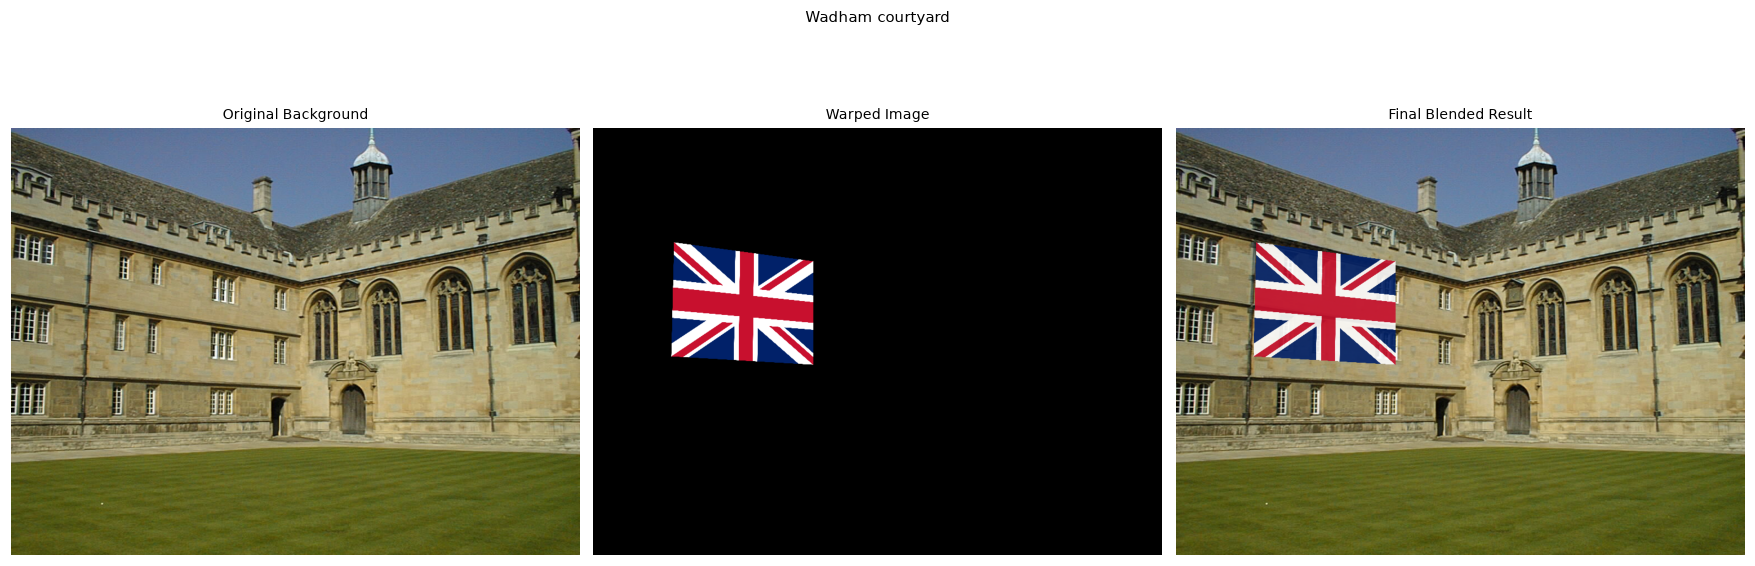

Sri Lankan flag on bus homography matrix:
[[3.51294242e-01 0.00000000e+00 3.50000000e+02]
 [7.23718965e-02 1.77777778e-01 2.88000000e+02]
 [2.64131009e-04 0.00000000e+00 1.00000000e+00]]


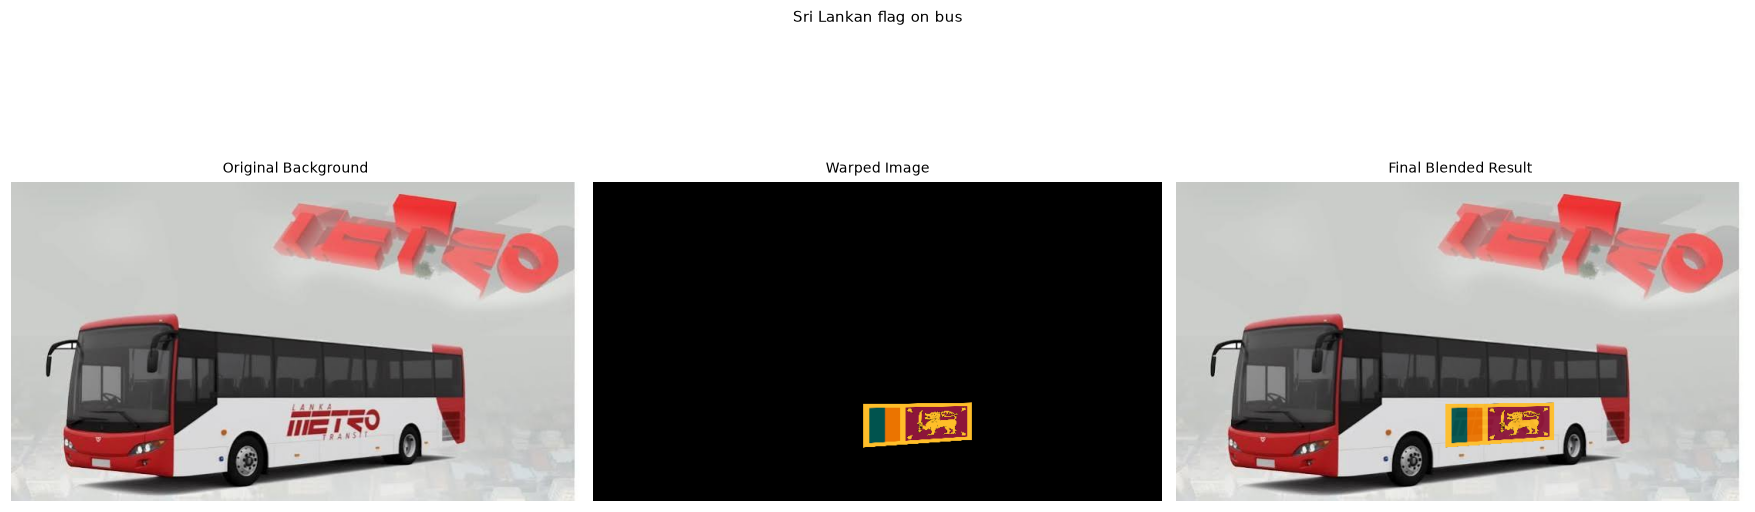

In [ ]:
def apply_homography(background, source, destination_points, alpha=0.9):
    h_src, w_src = source.shape[:2]
    h_bg, w_bg = background.shape[:2]
    source_points = np.float32([
        [0, 0], [w_src - 1, 0], [w_src - 1, h_src - 1], [0, h_src - 1]
    ])
    H = cv.getPerspectiveTransform(source_points, destination_points)
    warped = cv.warpPerspective(source, H, (w_bg, h_bg))

    mask = np.ones((h_src, w_src), dtype=np.uint8) * 255
    warped_mask = cv.warpPerspective(mask, H, (w_bg, h_bg))
    blend_mask = (alpha * warped_mask.astype(np.float32) / 255.0)[:, :, None]
    result = blend_mask * warped.astype(np.float32)
    result += (1 - blend_mask) * background.astype(np.float32)
    return H, warped, np.clip(result, 0, 255).astype(np.uint8)


# Set True to choose your own corners: TL, TR, BR, BL.
# Press R to restart, Enter to confirm, or Esc to cancel.
SELECT_POINTS = False
OUTPUT_DIR = Path("outputs/q3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pairs = [
    ("Wadham courtyard", "wadham.jpg", "flag.png",
     [[145, 205], [395, 239], [395, 425], [140, 410]], 0.9, "wadham"),
    ("Sri Lankan flag on bus", "bus.jpg", "sri_lanka_flag.png",
     [[350, 288], [490, 286], [490, 334], [350, 344]], 0.95, "bus"),
]

for title, background_name, source_name, corners, alpha, stem in pairs:
    background = read_image(IMAGE_DIR / background_name)
    source = read_image(IMAGE_DIR / source_name)
    if SELECT_POINTS:
        print(f"Select corners on {title}: TL, TR, BR, BL.")
        destination_points = select_four_points(background, title)
    else:
        destination_points = np.asarray(corners, dtype=np.float32)

    H, warped, result = apply_homography(
        background, source, destination_points, alpha=alpha
    )
    print(f"{title} homography matrix:")
    print(H)
    np.savetxt(OUTPUT_DIR / f"{stem}_homography.txt", H)
    cv.imwrite(str(OUTPUT_DIR / f"{stem}_warped.png"), warped)
    cv.imwrite(str(OUTPUT_DIR / f"{stem}_blended.png"), result)

    fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=False)
    for ax, image, image_title in zip(
        axes, [background, warped, result],
        ["Original Background", "Warped Image", "Final Blended Result"]
    ):
        show_image(ax, image, image_title)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{stem}_comparison.png", dpi=150)
    plt.show()


## 4. PCB alignment and difference detection

SIFT features are matched with a 0.8 Lowe ratio test. RANSAC estimates a homography with a 5-pixel threshold. Each PCB is warped into the reference frame, then absolute differences are thresholded at 40. An eroded validity mask excludes warped borders. Bright regions may also reflect lighting or registration errors, so they are candidate differences.


AAAA1.jpg: 98 good matches
ADAD1.jpg: 598 good matches
AECC2.jpg: 4929 good matches
AECC3.jpg: 6339 good matches
AECC4.jpg: 4404 good matches
AAAA1.jpg: 26 RANSAC inliers / 98 good matches
ADAD1.jpg: 238 RANSAC inliers / 598 good matches
AECC2.jpg: 4120 RANSAC inliers / 4929 good matches
AECC3.jpg: 5298 RANSAC inliers / 6339 good matches
AECC4.jpg: 3667 RANSAC inliers / 4404 good matches


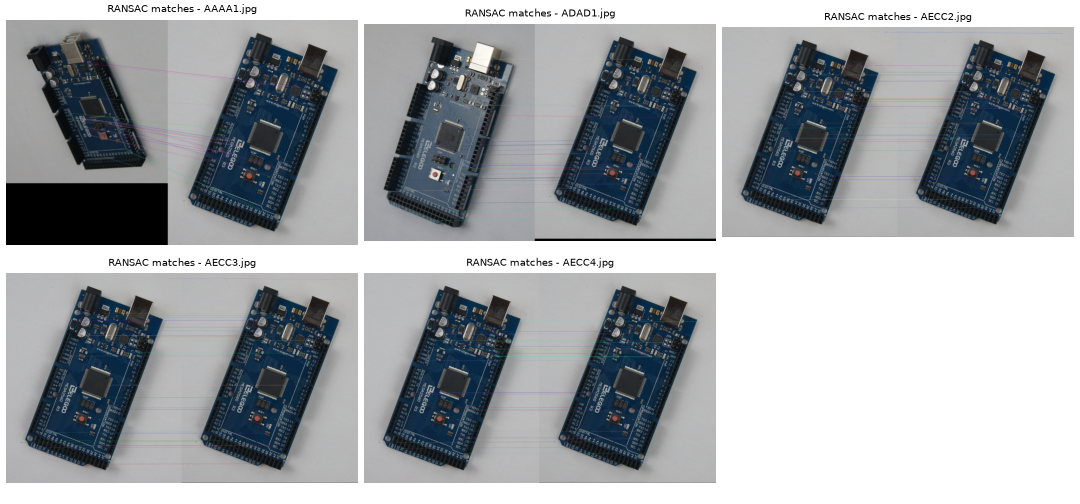

In [ ]:
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Load the reference and the five PCB images.
PCB_DIR = Path("images") / "pcb"
def read_pcb(name):
    path = PCB_DIR / name
    image = cv.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"Cannot read image: {path.resolve()}")
    return image

ref = read_pcb("AECC1.jpg")
pcb_names = ["AAAA1.jpg", "ADAD1.jpg", "AECC2.jpg", "AECC3.jpg", "AECC4.jpg"]
im_list = [read_pcb(name) for name in pcb_names]
gray_ref = cv.cvtColor(ref, cv.COLOR_BGR2GRAY)
gray_im_list = [cv.cvtColor(im, cv.COLOR_BGR2GRAY) for im in im_list]

# SIFT descriptors and two nearest neighbours with the L2 distance.
cv.setRNGSeed(42)
sift = cv.SIFT_create()
kp_ref, des_ref = sift.detectAndCompute(gray_ref, None)
kp_and_des_list = [sift.detectAndCompute(gray, None) for gray in gray_im_list]
if des_ref is None:
    raise ValueError("No SIFT descriptors found in the reference.")
bf = cv.BFMatcher(cv.NORM_L2)
good_matches = []
for name, (keypoints, descriptors) in zip(pcb_names, kp_and_des_list):
    matches = [] if descriptors is None else bf.knnMatch(descriptors, des_ref, k=2)
    good = [pair[0] for pair in matches
            if len(pair) == 2 and pair[0].distance < 0.8 * pair[1].distance]
    good_matches.append(good)
    print(f"{name}: {len(good)} good matches")

# Estimate the mapping from each PCB to the reference using RANSAC.
homography_list = []
inlier_mask_list = []
for name, (kp_im, _), good in zip(pcb_names, kp_and_des_list, good_matches):
    H, mask = None, None
    if len(good) >= 4:
        src_pts = np.float32([kp_im[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst_pts = np.float32([kp_ref[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        H, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
    homography_list.append(H)
    inlier_mask_list.append(mask)
    if H is None or mask is None:
        print(f"{name}: homography unavailable (insufficient or degenerate matches)")
    else:
        print(f"{name}: {int(mask.sum())} RANSAC inliers / {len(good)} good matches")

fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), constrained_layout=False)
for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i >= len(im_list):
        continue
    ax.set_title(f"RANSAC matches - {pcb_names[i]}", fontsize=8)
    if homography_list[i] is None:
        ax.text(0.5, 0.5, "Homography estimation failed", ha="center")
        continue
    # Show at most 25 evenly spaced inliers to keep the lines readable.
    inlier_ids = np.flatnonzero(inlier_mask_list[i].ravel())
    selected = inlier_ids[np.linspace(0, len(inlier_ids) - 1,
                                    min(25, len(inlier_ids)), dtype=int)]
    display_mask = np.zeros(len(good_matches[i]), dtype=np.uint8)
    display_mask[selected] = 1
    matched_image = cv.drawMatches(
        im_list[i], kp_and_des_list[i][0], ref, kp_ref, good_matches[i], None,
        matchesMask=display_mask.tolist(),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    ax.imshow(cv.cvtColor(matched_image, cv.COLOR_BGR2RGB))
fig.tight_layout(pad=0.5, h_pad=1.2, w_pad=0.5)
plt.show()


AAAA1.jpg: alignment completed
ADAD1.jpg: alignment completed
AECC2.jpg: alignment completed
AECC3.jpg: alignment completed
AECC4.jpg: alignment completed


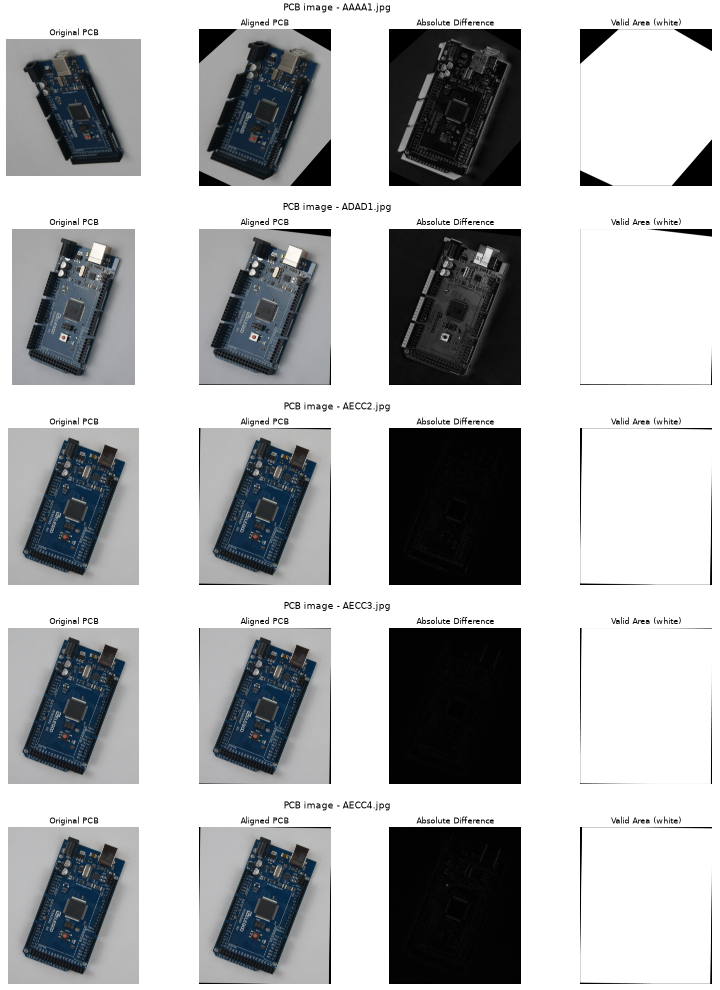

In [ ]:
# Align each PCB and compare it with the reference.
aligned_images = []
difference_images = []
binary_difference_images = []
valid_masks = []
h, w = ref.shape[:2]
for name, im, H in zip(pcb_names, im_list, homography_list):
    if H is None:
        valid_masks.append(None)
        aligned_images.append(None)
        difference_images.append(None)
        binary_difference_images.append(None)
        continue
    aligned = cv.warpPerspective(im, H, (w, h))
    valid_mask = cv.warpPerspective(
        np.full(im.shape[:2], 255, dtype=np.uint8), H, (w, h),
        flags=cv.INTER_NEAREST)
    valid_mask = cv.erode(valid_mask, np.ones((5, 5), np.uint8),
                          borderType=cv.BORDER_CONSTANT, borderValue=0)
    difference = cv.absdiff(ref, aligned)
    difference_gray = cv.cvtColor(difference, cv.COLOR_BGR2GRAY)
    difference_gray[valid_mask == 0] = 0
    _, difference_binary = cv.threshold(difference_gray, 40, 255, cv.THRESH_BINARY)
    valid_masks.append(valid_mask)
    aligned_images.append(aligned)
    difference_images.append(difference_gray)
    binary_difference_images.append(difference_binary)
    print(f"{name}: alignment completed")

# One compact comparison grid, with one row per PCB image.
fig, axes = plt.subplots(len(pcb_names), 4, figsize=(8, 11),
                         constrained_layout=False)
for i, name in enumerate(pcb_names):
    for ax in axes[i]:
        ax.axis("off")
    if aligned_images[i] is None:
        axes[i, 0].text(0.5, 0.5, f"{name}: alignment failed", ha="center")
        continue
    axes[i, 0].imshow(cv.cvtColor(im_list[i], cv.COLOR_BGR2RGB))
    axes[i, 1].imshow(cv.cvtColor(aligned_images[i], cv.COLOR_BGR2RGB))
    axes[i, 2].imshow(difference_images[i], cmap="gray", vmin=0, vmax=255)
    axes[i, 3].imshow(valid_masks[i], cmap="gray", vmin=0, vmax=255)
    for ax, title in zip(axes[i], ["Original PCB", "Aligned PCB",
                                   "Absolute Difference", "Valid Area (white)"]):
        ax.set_title(title, fontsize=6, pad=3)
    axes[i, 1].text(1.05, 1.12, f"PCB image - {name}",
                    transform=axes[i, 1].transAxes, ha="center", fontsize=7)
fig.tight_layout(pad=0.5, h_pad=1.6, w_pad=0.6)
plt.show()
